## 一、資料預處理

In [33]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras import utils
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.keras.utils.set_random_seed(10)
np.set_printoptions(formatter={'float_kind': lambda value: str(round(float(value), 8))})
print('TensorFlow：', tf.__version__)

TensorFlow： 2.21.0


In [34]:
(x_train_image, y_train_label), (x_test_image, y_test_label) = fashion_mnist.load_data()

class_names = np.array([
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
])

print('訓練圖片形狀：', x_train_image.shape)
print('訓練標籤形狀：', y_train_label.shape)
print('測試圖片形狀：', x_test_image.shape)
print('測試標籤形狀：', y_test_label.shape)
print(np.array(class_names))

訓練圖片形狀： (60000, 28, 28)
訓練標籤形狀： (60000,)
測試圖片形狀： (10000, 28, 28)
測試標籤形狀： (10000,)
['T-shirt/top' 'Trouser' 'Pullover' 'Dress' 'Coat' 'Sandal' 'Shirt'
 'Sneaker' 'Bag' 'Ankle boot']


### 顯示訓練圖片與真實標籤名稱

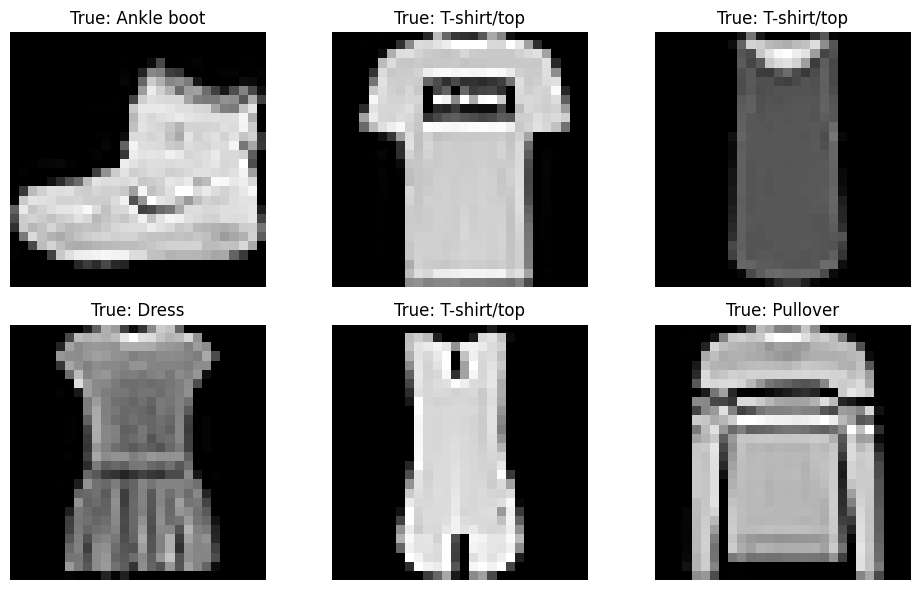

In [35]:
plt.figure(figsize=(10, 6))
for i in range(6):
    ax = plt.subplot(2, 3, i + 1)
    ax.imshow(x_train_image[i], cmap='gray')
    ax.set_title('True: ' + class_names[y_train_label[i]])
    ax.axis('off')
plt.tight_layout()
plt.show()

In [36]:
x_Train = x_train_image.reshape(60000, 784).astype('float32')
x_Test = x_test_image.reshape(10000, 784).astype('float32')

x_Train_normalize = x_Train / 255.0
x_Test_normalize = x_Test / 255.0

y_Train_OneHot = utils.to_categorical(y_train_label, 10)
y_Test_OneHot = utils.to_categorical(y_test_label, 10)

print('訓練輸入形狀：', x_Train_normalize.shape)
print('測試輸入形狀：', x_Test_normalize.shape)
print('訓練 one-hot 形狀：', y_Train_OneHot.shape)
print('測試 one-hot 形狀：', y_Test_OneHot.shape)
print('第一筆 one-hot：', np.array(y_Train_OneHot[0]))

訓練輸入形狀： (60000, 784)
測試輸入形狀： (10000, 784)
訓練 one-hot 形狀： (60000, 10)
測試 one-hot 形狀： (10000, 10)
第一筆 one-hot： [0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 1.0]


## 二、建立模型



In [49]:
model = Sequential()
model.add(Input(shape=(784,)))
model.add(Dense(units=1000, kernel_initializer='he_normal', activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(units=1000, kernel_initializer='he_normal', activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(units=10, kernel_initializer='normal', activation='softmax'))

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 1000)           │       785,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 1000)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1000)           │     1,001,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 1000)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │        10,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,796,010 (6.85 MB)

 Trainable params: 1,796,010 (6.85 MB)

 Non-trainable params: 0 (0.00 B)

## 三、訓練模型


In [50]:
model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

In [51]:
callbacks = [
    EarlyStopping(monitor='val_accuracy', mode='max', patience=8,
                  restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3,
                      min_lr=0.00001)
]

train_history = model.fit(
    x=x_Train_normalize,
    y=y_Train_OneHot,
    validation_split=0.2,
    epochs=50,
    batch_size=200,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/50
240/240 - 4s - 17ms/step - accuracy: 0.8021 - loss: 0.5554 - val_accuracy: 0.8589 - val_loss: 0.3959 - learning_rate: 0.0010
Epoch 2/50
240/240 - 1s - 5ms/step - accuracy: 0.8551 - loss: 0.4019 - val_accuracy: 0.8698 - val_loss: 0.3574 - learning_rate: 0.0010
Epoch 3/50
240/240 - 1s - 5ms/step - accuracy: 0.8661 - loss: 0.3654 - val_accuracy: 0.8756 - val_loss: 0.3417 - learning_rate: 0.0010
Epoch 4/50
240/240 - 1s - 5ms/step - accuracy: 0.8721 - loss: 0.3427 - val_accuracy: 0.8775 - val_loss: 0.3309 - learning_rate: 0.0010
Epoch 5/50
240/240 - 1s - 5ms/step - accuracy: 0.8789 - loss: 0.3243 - val_accuracy: 0.8761 - val_loss: 0.3326 - learning_rate: 0.0010
Epoch 6/50
240/240 - 1s - 5ms/step - accuracy: 0.8841 - loss: 0.3115 - val_accuracy: 0.8787 - val_loss: 0.3252 - learning_rate: 0.0010
Epoch 7/50
240/240 - 1s - 5ms/step - accuracy: 0.8888 - loss: 0.2995 - val_accuracy: 0.8852 - val_loss: 0.3165 - learning_rate: 0.0010
Epoch 8/50
240/240 - 1s - 5ms/step - accuracy: 0.8905 

## 四、以圖形顯示訓練過程


In [52]:
def show_train_history(train_history, train, validation):
    epochs = range(1, len(train_history.history[train]) + 1)
    plt.figure(figsize=(7, 4))
    plt.plot(epochs, train_history.history[train], label='train')
    plt.plot(epochs, train_history.history[validation], label='validation')
    plt.title('Train History')
    plt.ylabel(train)
    plt.xlabel('Epoch')
    plt.legend()
    plt.tight_layout()
    plt.show()

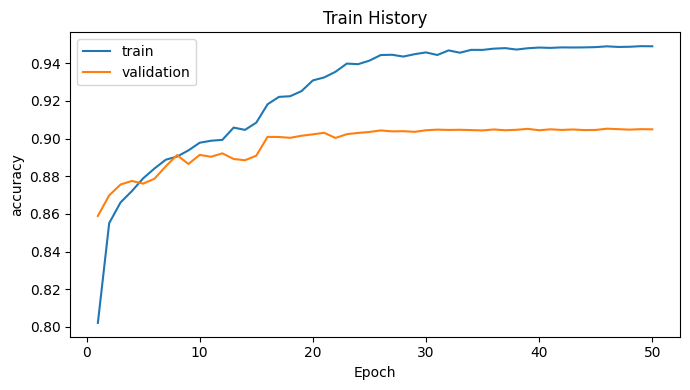

In [53]:
show_train_history(train_history, 'accuracy', 'val_accuracy')

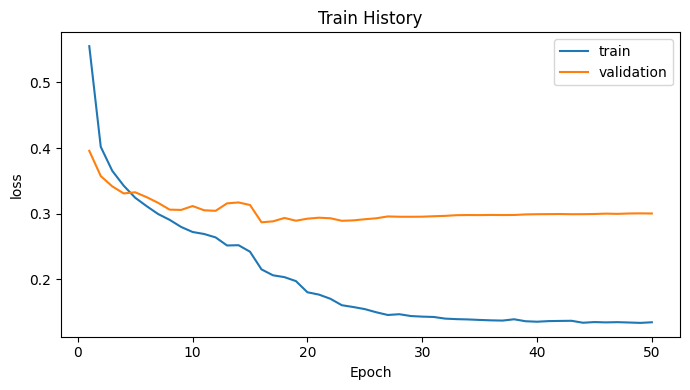

In [54]:
show_train_history(train_history, 'loss', 'val_loss')

## 五、評估模型準確率


In [55]:
scores = model.evaluate(x_Test_normalize, y_Test_OneHot, verbose=2)
print('測試 loss：', scores[0])
print('測試 accuracy：{:.2%}'.format(scores[1]))

313/313 - 1s - 5ms/step - accuracy: 0.9018 - loss: 0.3191
測試 loss： 0.31910470128059387
測試 accuracy：90.18%


## 六、進行預測


In [56]:
prediction = model.predict(x_Test_normalize, verbose=2)
predicted_labels = np.argmax(prediction, axis=1)

print('prediction.shape：', prediction.shape)
print('predicted_labels.shape：', predicted_labels.shape)
print('前十筆預測名稱：', np.array(class_names[predicted_labels[:10]]))
print('前十筆真實名稱：', np.array(class_names[y_test_label[:10]]))

313/313 - 1s - 2ms/step
prediction.shape： (10000, 10)
predicted_labels.shape： (10000,)
前十筆預測名稱： ['Ankle boot' 'Pullover' 'Trouser' 'Trouser' 'Shirt' 'Trouser' 'Coat'
 'Shirt' 'Sandal' 'Sneaker']
前十筆真實名稱： ['Ankle boot' 'Pullover' 'Trouser' 'Trouser' 'Shirt' 'Trouser' 'Coat'
 'Shirt' 'Sandal' 'Sneaker']


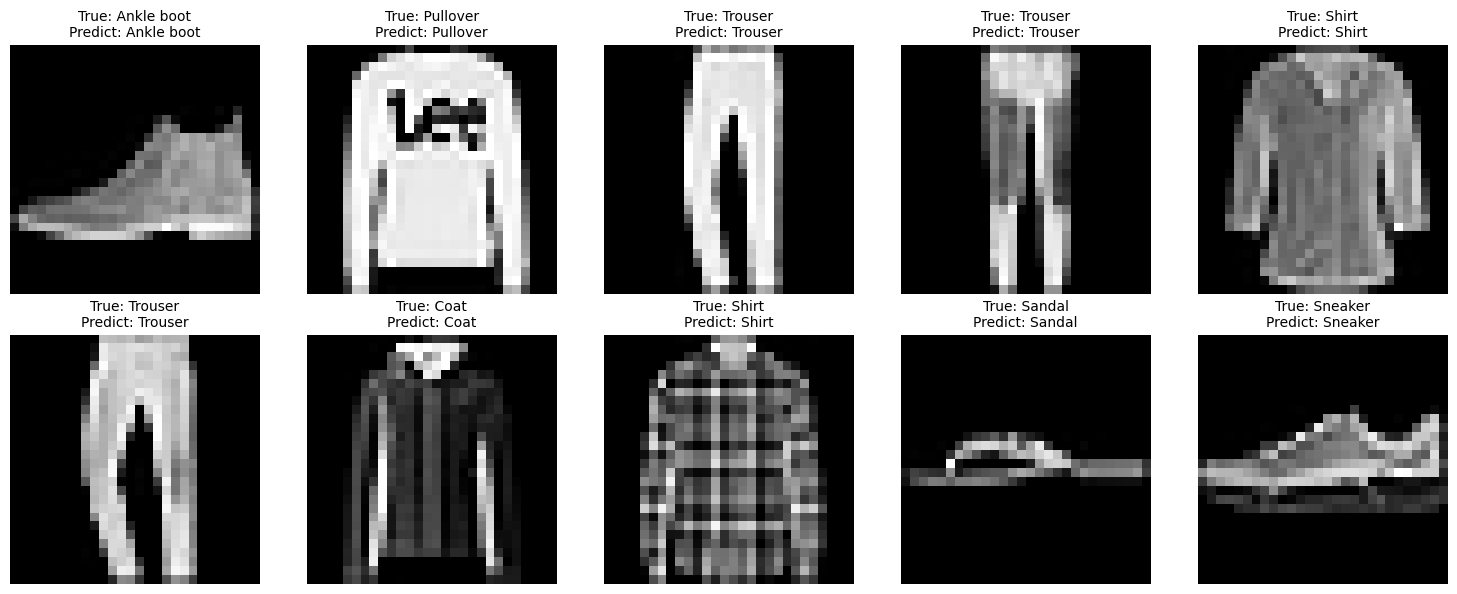

In [57]:
def plot_images_labels_prediction(images, labels, prediction, idx=0, num=10):
    num = min(num, 25, len(images) - idx)
    rows = (num + 4) // 5
    plt.figure(figsize=(15, rows * 3))
    for i in range(num):
        index = idx + i
        ax = plt.subplot(rows, 5, i + 1)
        ax.imshow(images[index], cmap='gray')
        ax.set_title('True: ' + class_names[labels[index]] +
                     '\nPredict: ' + class_names[np.argmax(prediction[index])],
                     fontsize=10)
        ax.axis('off')
    plt.tight_layout()
    plt.show()


plot_images_labels_prediction(x_test_image, y_test_label, prediction)

## 七、Confusion matrix（混淆矩陣）


In [58]:
confusion = pd.crosstab(
    pd.Series(y_test_label, name='True'),
    pd.Series(predicted_labels, name='Predicted')
).reindex(index=range(10), columns=range(10), fill_value=0)

confusion.index = class_names
confusion.columns = class_names
print(confusion.to_string())

             T-shirt/top  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker  Bag  Ankle boot
T-shirt/top          861        2        14     18     2       0     98        0    5           0
Trouser                1      980         1     11     3       0      3        0    1           0
Pullover              13        1       838     11    72       0     65        0    0           0
Dress                 15        6        10    917    30       0     19        0    3           0
Coat                   1        0        90     31   822       0     55        0    1           0
Sandal                 0        0         0      0     0     972      0       16    1          11
Shirt                106        0        82     31    54       0    719        0    8           0
Sneaker                0        0         0      0     0      10      0      972    0          18
Bag                    5        0         4      3     3       2      4        3  976           0
Ankle boot          

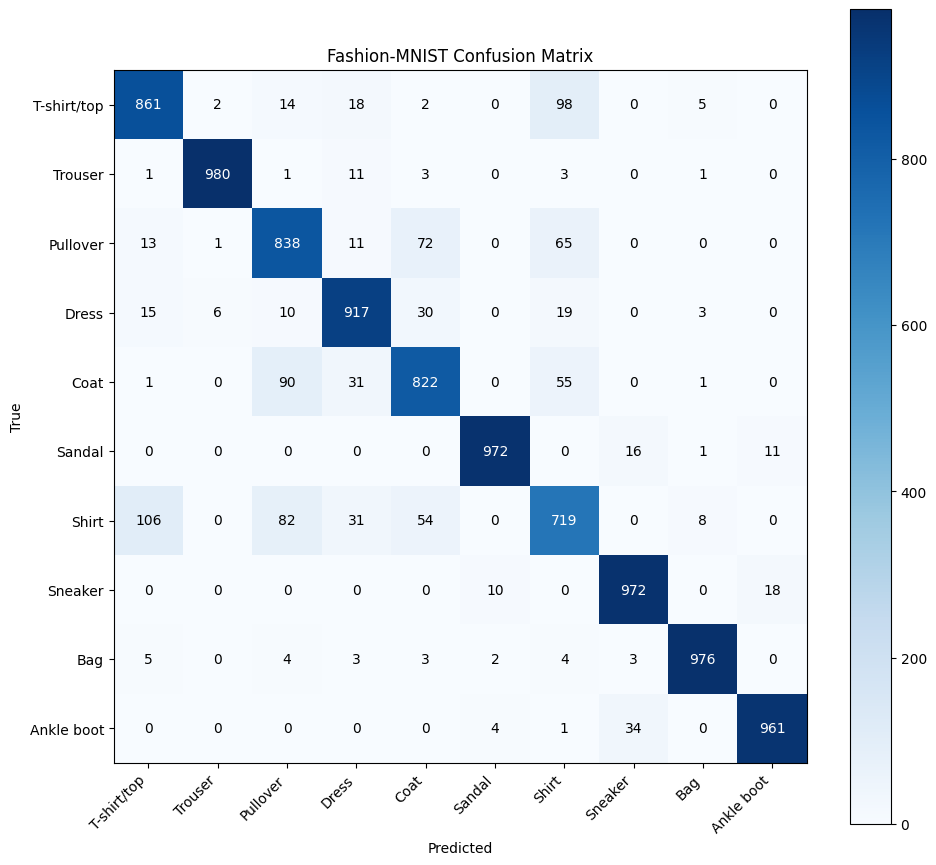

In [59]:
cm = confusion.to_numpy()
fig, ax = plt.subplots(figsize=(10, 9))
image = ax.imshow(cm, cmap='Blues')
fig.colorbar(image, ax=ax)
ax.set_xticks(range(10), labels=class_names, rotation=45, ha='right')
ax.set_yticks(range(10), labels=class_names)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title('Fashion-MNIST Confusion Matrix')
for i in range(10):
    for j in range(10):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.tight_layout()
plt.show()

## 八、儲存完整模型


In [48]:
model.save('fashion_mnist_dnn.keras')
print('完整模型已儲存：fashion_mnist_dnn.keras')

完整模型已儲存：fashion_mnist_dnn.keras
